In [1]:
import os
import numpy as np
import pandas as pd
from tqdm import tqdm
from operator import itemgetter
from collections import OrderedDict

from PIL import Image
import seaborn as sns
import matplotlib.pyplot as plt

import torch
from torch import optim,nn
import torch.nn.functional as F
from torchvision import transforms as T,models
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision.utils import make_grid

pd.options.plotting.backend = "plotly"
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# EDA

In [2]:
data = pd.read_csv('../input/sample/sample_labels.csv')
data.head()

,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Gender,View Position,OriginalImageWidth,OriginalImageHeight,OriginalImagePixelSpacing_x,OriginalImagePixelSpacing_y
0,00000013_005.png,Emphysema|Infiltration|Pleural_Thickening|Pneu...,5,13,060Y,M,AP,3056,2544,0.139,0.139
1,00000013_026.png,Cardiomegaly|Emphysema,26,13,057Y,M,AP,2500,2048,0.168,0.168
2,00000017_001.png,No Finding,1,17,077Y,M,AP,2500,2048,0.168,0.168
3,00000030_001.png,Atelectasis,1,30,079Y,M,PA,2992,2991,0.143,0.143
4,00000032_001.png,Cardiomegaly|Edema|Effusion,1,32,055Y,F,AP,2500,2048,0.168,0.168


In [3]:
data['Patient Gender'].value_counts().plot.bar()

In [4]:
data['Patient Age'].apply(lambda x : int(x[1:3])).plot.hist()

In [5]:
data['Patient Age'].apply(lambda x : int(x[1:3])).plot.box()

In [6]:
data['View Position'].value_counts().plot.bar()

In [7]:
pathology_list = ['Cardiomegaly','Emphysema','Effusion','Hernia','Nodule','Pneumothorax','Atelectasis','Pleural_Thickening','Mass','Edema','Consolidation','Infiltration','Fibrosis','Pneumonia']

for pathology in pathology_list :
    data[pathology] = data['Finding Labels'].apply(lambda x: 1 if pathology in x else 0)
    
data['No Findings'] = data['Finding Labels'].apply(lambda x: 1 if 'No Finding' in x else 0)

In [8]:
data = data.drop(list(data.iloc[:,1:11].columns.values),axis = 1)
data.iloc[:,1:].sum().plot.barh()

In [9]:
data = data.drop(['No Findings'],axis = 1)
data.iloc[:,1:].sum().plot.barh()

In [10]:
data.iloc[:,1:].mean().plot.barh()

# Avoid Data Imbalance using Weighted Loss

In [11]:
def compute_class_freqs(labels):

    labels = np.array(labels)
    N = labels.shape[0]

    positive_frequencies = np.sum(labels, axis = 0) / N
    negative_frequencies = 1 - positive_frequencies

    return positive_frequencies, negative_frequencies

In [12]:
freq_pos,freq_neg = compute_class_freqs(data.iloc[:,1:])

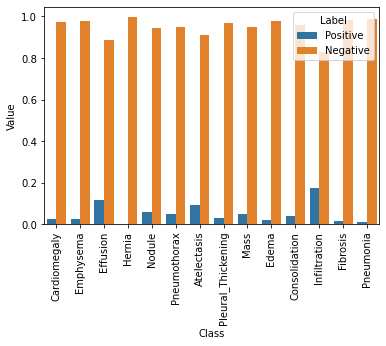

In [13]:
df = pd.DataFrame({"Class": pathology_list, "Label": "Positive", "Value": freq_pos})
df = df.append([{"Class": pathology_list[l], "Label": "Negative", "Value": v} for l,v in enumerate(freq_neg)], ignore_index=True)

plt.xticks(rotation=90)
f = sns.barplot(x="Class", y="Value", hue="Label" ,data=df)

In [14]:
pos_weights = freq_neg
neg_weights = freq_pos
pos_contribution = freq_pos * pos_weights 
neg_contribution = freq_neg * neg_weights

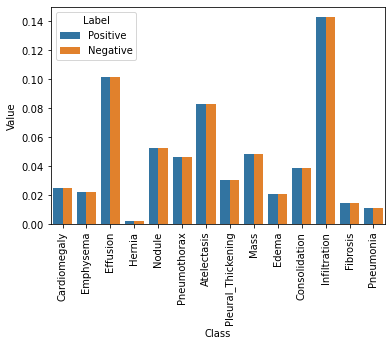

In [15]:
df = pd.DataFrame({"Class": pathology_list, "Label": "Positive", "Value": pos_contribution})
df = df.append([{"Class": pathology_list[l], "Label": "Negative", "Value": v} for l,v in enumerate(neg_contribution)], ignore_index=True)

plt.xticks(rotation=90)
f = sns.barplot(x="Class", y="Value", hue="Label" ,data=df)

In [16]:
def weighted_loss(pos_weights, neg_weights, y_pred, y_true, epsilon=1e-7):

    loss = 0.0
    for i in range(len(pos_weights)):
        loss_pos = -1 * torch.mean(pos_weights[i] * y_true[:,i] * torch.log(y_pred[:,i] + epsilon))
        loss_neg = -1 * torch.mean(neg_weights[i] * (1-y_true[:,i]) * torch.log((1-y_pred[:,i]) + epsilon))
        loss += loss_pos + loss_neg
    return loss

# Loading Dataset and Applying Transforms

In [17]:
class NIH_Dataset(Dataset):

    def __init__(self, data, img_dir, transform=None):
        self.data = data
        self.img_dir = img_dir 
        self.transform = transform 

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        img_file = self.img_dir + self.data.iloc[:,0][idx]
        img = Image.open(img_file).convert('RGB')
        label = np.array(self.data.iloc[:,1:].iloc[idx])

        if self.transform:
            img = self.transform(img)

        return img,label

In [18]:
data_transform = T.Compose([
    T.RandomRotation((-20,+20)),
    T.Resize((224,224)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225])
])

In [19]:
trainds = NIH_Dataset(data,
                      img_dir = '../input/sample/sample/sample/images/',
                      transform = data_transform)

In [20]:
def deprocess(img):
    img = img.permute(1,2,0)
    img = img * torch.Tensor([0.229, 0.224, 0.225]) + torch.Tensor([0.485, 0.456, 0.406])
    return img

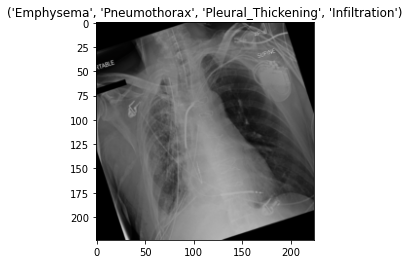

In [21]:
image, label = trainds[0]
class_labels = list(np.where(label==1)[0])
plt.imshow(deprocess(image))
plt.title(itemgetter(*class_labels)(pathology_list));

# Split Dataset and create dataloaders

In [22]:
trainset, validset, testset = random_split(trainds, [5000,303,303])

print("Length of trainset : {}".format(len(trainset)))
print("Length of testset : {}".format(len(testset)))
print("Length of validset : {}".format(len(validset)))

Length of trainset : 5000
Length of testset : 303
Length of validset : 303


In [23]:
trainloader = DataLoader(trainset,
                         batch_size = 32,
                         shuffle = True)

validloader = DataLoader(validset,
                         batch_size = 32,
                         shuffle = False)

testloader = DataLoader(testset,
                        batch_size = 32,
                        shuffle = True)

# Define Pre-trained Model

In [24]:
model = models.resnet18()
model.load_state_dict(torch.load('../input/pretrained-model-weights-pytorch/resnet18-5c106cde.pth'))

<All keys matched successfully>

In [25]:
for param in model.parameters():
    param.requires_grad = False

model.fc = nn.Sequential(
    nn.Linear(512, 14),
    nn.Sigmoid()
)

model.to(device)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

# Train Model 

In [26]:
optimizer = optim.Adam(model.parameters(),
                       lr = 0.0001)
schedular = optim.lr_scheduler.ReduceLROnPlateau(optimizer,
                                                 factor = 0.1,
                                                 patience = 4)
epochs = 15
valid_loss_min = np.Inf

In [27]:
for i in range(epochs):

    train_loss = 0.0
    valid_loss = 0.0
    train_acc = 0.0
    valid_acc = 0.0 

    model.train()
    for images,labels in tqdm(trainloader):
        images = images.to(device)
        labels = labels.to(device)

        ps = model(images)
        loss = weighted_loss(pos_weights,neg_weights,ps,labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
    avg_train_loss = train_loss / len(trainloader)

    model.eval()
    with torch.no_grad():
        for images,labels in tqdm(validloader):
            images = images.to(device)
            labels = labels.to(device)

            ps = model(images)
            loss = weighted_loss(pos_weights,neg_weights,ps,labels)
            valid_loss += loss.item()
        avg_valid_loss = valid_loss / len(validloader)

    schedular.step(avg_valid_loss)

    if avg_valid_loss <= valid_loss_min:
        print('Validation loss decreased ({:.6f} --> {:.6f}).   Saving model ...'.format(valid_loss_min,avg_valid_loss))
        torch.save({
            'epoch' : i,
            'model_state_dict' : model.state_dict(),
            'optimizer_state_dict' : optimizer.state_dict(),
            'valid_loss_min' : avg_valid_loss
        },'Pneumonia_model.pt')

        valid_loss_min = avg_valid_loss

    print("Epoch : {} Train Loss : {:.6f} ".format(i+1,avg_train_loss))
    print("Epoch : {} Valid Loss : {:.6f} ".format(i+1,avg_valid_loss))

  0%|          | 0/157 [00:00<?, ?it/s]

Validation loss decreased (inf --> 0.921567).   Saving model ...
Epoch : 1 Train Loss : 0.903078 
Epoch : 1 Valid Loss : 0.921567 


  0%|          | 0/157 [00:00<?, ?it/s]

Validation loss decreased (0.921567 --> 0.902701).   Saving model ...
Epoch : 2 Train Loss : 0.877478 
Epoch : 2 Valid Loss : 0.902701 


  0%|          | 0/157 [00:00<?, ?it/s]

...

Epoch : 13 Train Loss : 0.816654 
Epoch : 13 Valid Loss : 0.871066 


  0%|          | 0/157 [00:00<?, ?it/s]

Validation loss decreased (0.862757 --> 0.855093).   Saving model ...
Epoch : 14 Train Loss : 0.817912 
Epoch : 14 Valid Loss : 0.855093 


100%|██████████| 10/10 [00:08<00:00,  1.21it/s]

Epoch : 15 Train Loss : 0.812757 
Epoch : 15 Valid Loss : 0.864346 


# Each Class Accuracy 

In [28]:
def class_accuracy(dataloader, model):

    per_class_accuracy = [0 for i in range(len(pathology_list))]
    total = 0.0

    with torch.no_grad():
        for images,labels in dataloader:
            ps = model(images.to(device))
            labels = labels.to(device)
            ps = (ps >= 0.5).float()

            for i in range(ps.shape[1]):
                x1 = ps[:,i:i+1]
                x2 = labels[:,i:i+1]
                per_class_accuracy[i] += int((x1 == x2).sum())

        per_class_accuracy = [(i/len(dataloader.dataset))*100.0 for i in per_class_accuracy]

    return per_class_accuracy     


def get_acc_data(class_names,acc_list):
    df = pd.DataFrame(list(zip(class_names, acc_list)), columns =['Labels', 'Acc']) 
    return df 

In [29]:
print("Train Dataset Accuracy Report")
acc_list = class_accuracy(trainloader, model)
get_acc_data(pathology_list,acc_list)

Train Dataset Accuracy Report


,Labels,Acc
0,Cardiomegaly,49.40
1,Emphysema,66.46
2,Effusion,67.30
3,Hernia,85.86
4,Nodule,64.16
5,Pneumothorax,73.96
6,Atelectasis,63.96
7,Pleural_Thickening,59.20
8,Mass,52.24
9,Edema,64.70


In [30]:
print("Test Dataset Accuracy Report")
acc_list = class_accuracy(testloader, model)
get_acc_data(pathology_list,acc_list)

Test Dataset Accuracy Report


,Labels,Acc
0,Cardiomegaly,44.224422
1,Emphysema,62.376238
2,Effusion,66.996700
3,Hernia,85.808581
4,Nodule,57.095710
5,Pneumothorax,70.957096
6,Atelectasis,61.716172
7,Pleural_Thickening,57.425743
8,Mass,54.785479
9,Edema,66.006601


In [31]:
print("Valid Dataset Accuracy Report")
acc_list = class_accuracy(validloader, model)
get_acc_data(pathology_list,acc_list)

Valid Dataset Accuracy Report


,Labels,Acc
0,Cardiomegaly,52.805281
1,Emphysema,66.666667
2,Effusion,67.656766
3,Hernia,87.788779
4,Nodule,59.405941
5,Pneumothorax,72.607261
6,Atelectasis,64.686469
7,Pleural_Thickening,54.125413
8,Mass,55.445545
9,Edema,67.656766


# Plot Results

In [32]:
def view_classify(img, ps, label):

    class_name = pathology_list
    classes = np.array(class_name)

    ps = ps.cpu().data.numpy().squeeze()
    img = deprocess(img)
    class_labels = list(np.where(label==1)[0])

    if not class_labels :
        title = 'No Findings'
    else : 
        title = itemgetter(*class_labels)(class_name)


    fig, (ax1, ax2) = plt.subplots(figsize=(8,12), ncols=2)
    ax1.imshow(img)
    ax1.set_title('Ground Truth : {}'.format(title))
    ax1.axis('off')
    ax2.barh(classes, ps)
    ax2.set_aspect(0.1)
    ax2.set_yticks(classes)
    ax2.set_yticklabels(classes)
    ax2.set_title('Predicted Class')
    ax2.set_xlim(0, 1.1)

    plt.tight_layout()

    return None

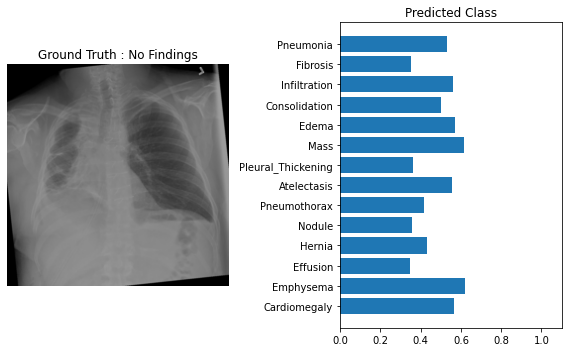

In [33]:
image,label = testset[123]

ps = model(image.unsqueeze(0).to(device))

view_classify(image,ps,label)

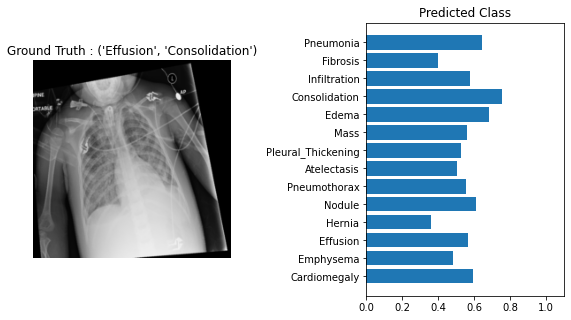

In [34]:
image,label = trainset[999]

ps = model(image.unsqueeze(0).to(device))

view_classify(image,ps,label)

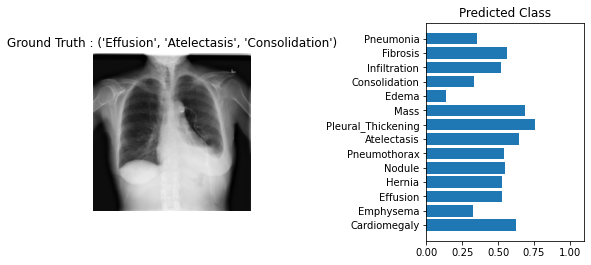

In [35]:
image,label = validset[234]

ps = model(image.unsqueeze(0).to(device))

view_classify(image,ps,label)